In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path

In [28]:
DATA_PATH = Path(
    r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\TerraSpectra_Synthetic_Demo_Dataset\synthetic_hsi_demo.npz"
)

data = np.load(DATA_PATH)

cube = data["cube"]
labels = data["labels"]
wavelengths = data["wavelengths_nm"]

In [29]:
print("Hyperspectral cube shape:", cube.shape)
print("Labels shape:", labels.shape)
print("Number of spectral bands:", len(wavelengths))

print("Unique labels:", np.unique(labels))

Hyperspectral cube shape: (32, 32, 16)
Labels shape: (32, 32)
Number of spectral bands: 16
Unique labels: [0 1]


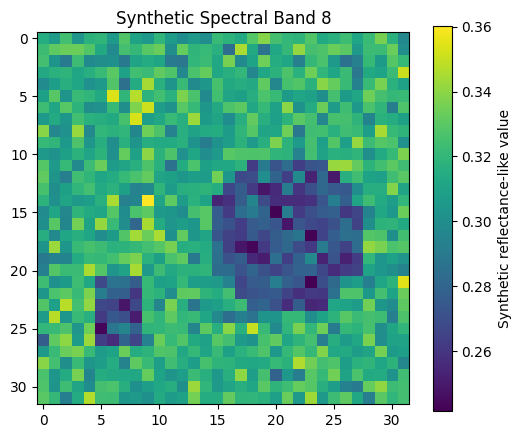

In [30]:
plt.figure(figsize=(6, 5))

plt.imshow(cube[:, :, 7], cmap="viridis")
plt.title("Synthetic Spectral Band 8")
plt.colorbar(label="Synthetic reflectance-like value")

plt.show()

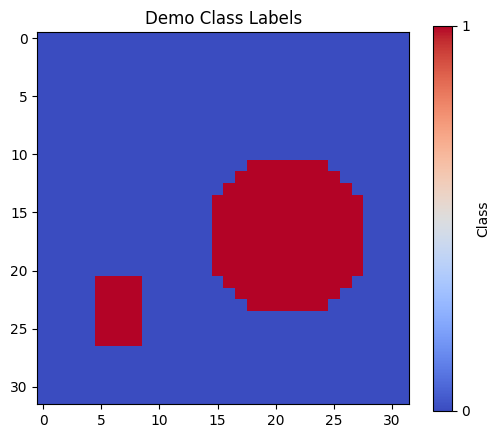

In [31]:
plt.figure(figsize=(6, 5))

plt.imshow(labels, cmap="coolwarm", vmin=0, vmax=1)
plt.title("Demo Class Labels")
plt.colorbar(ticks=[0, 1], label="Class")

plt.show()

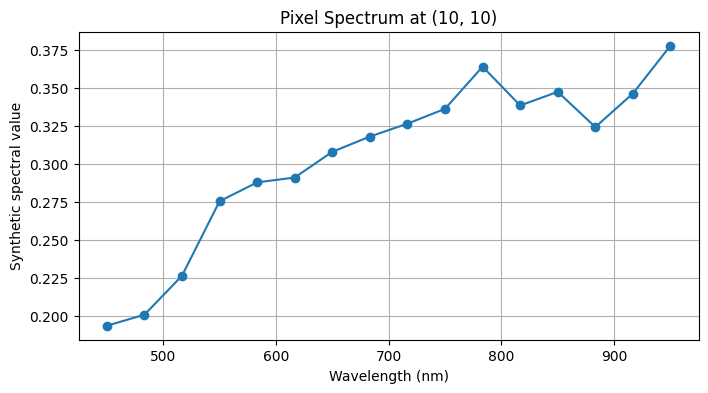

In [32]:
row = 10
col = 10

spectrum = cube[row, col, :]

plt.figure(figsize=(8, 4))

plt.plot(wavelengths, spectrum, marker="o")
plt.xlabel("Wavelength (nm)")
plt.ylabel("Synthetic spectral value")
plt.title(f"Pixel Spectrum at ({row}, {col})")
plt.grid(True)

plt.show()

In [33]:
csv_path = DATA_PATH.parent / "pixel_spectra.csv"

df = pd.read_csv(csv_path)

df.head()

,row,col,label,class_name,band_01,band_02,band_03,band_04,band_05,band_06,band_07,band_08,band_09,band_10,band_11,band_12,band_13,band_14,band_15,band_16
0,0,0,0,healthy_demo,0.185869,0.196336,0.243337,0.269057,0.254921,0.279858,0.310529,0.315177,0.325640,0.320079,0.343874,0.345257,0.340012,0.357773,0.357493,0.352457
1,0,1,0,healthy_demo,0.163611,0.212262,0.226637,0.248457,0.263067,0.303059,0.300045,0.306736,0.314521,0.329608,0.330612,0.333781,0.337294,0.362851,0.339910,0.349527
2,0,2,0,healthy_demo,0.189126,0.221886,0.232486,0.247211,0.267962,0.302813,0.317436,0.325011,0.317378,0.332623,0.334244,0.338070,0.349199,0.346452,0.359552,0.363102
3,0,3,0,healthy_demo,0.184801,0.186343,0.225509,0.247139,0.265681,0.287196,0.321947,0.303595,0.332474,0.305134,0.324316,0.332890,0.341267,0.347794,0.356416,0.353597
4,0,4,0,healthy_demo,0.183121,0.197133,0.209635,0.234783,0.257913,0.292062,0.301316,0.317870,0.311327,0.322830,0.331441,0.322823,0.335313,0.326916,0.338138,0.348800


In [34]:
# avalabality 
print(df.columns)
print(df.shape)

Index(['row', 'col', 'label', 'class_name', 'band_01', 'band_02', 'band_03',
       'band_04', 'band_05', 'band_06', 'band_07', 'band_08', 'band_09',
       'band_10', 'band_11', 'band_12', 'band_13', 'band_14', 'band_15',
       'band_16'],
      dtype='object')
(1024, 20)


In [35]:
print("Cube shape:", cube.shape)
print("Labels shape:", labels.shape)

assert cube.shape == (32, 32, 16)
assert labels.shape == (32, 32)

print("Unique labels:", np.unique(labels))

Cube shape: (32, 32, 16)
Labels shape: (32, 32)
Unique labels: [0 1]


In [36]:
unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    print(f"Class {label}: {count} pixels")

Class 0: 855 pixels
Class 1: 169 pixels


In [37]:
X = cube.reshape(-1, 16)
y = labels.reshape(-1)



# STEP 1: Check spatial class distribution

print("\n--- Spatial Class Distribution ---")

for row in range(labels.shape[0]):
    healthy = np.sum(labels[row, :] == 0)
    stress = np.sum(labels[row, :] == 1)

    print(
        f"Row {row:02d} | "
        f"Healthy: {healthy:02d} | "
        f"Stress: {stress:02d}"
    )

print("\n--- Overall Distribution ---")

unique, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique, counts):
    class_name = "Healthy" if label == 0 else "Stress"
    print(f"{class_name}: {count}")


print("X:", X.shape)
print("y:", y.shape)


--- Spatial Class Distribution ---
Row 00 | Healthy: 32 | Stress: 00
Row 01 | Healthy: 32 | Stress: 00
Row 02 | Healthy: 32 | Stress: 00
Row 03 | Healthy: 32 | Stress: 00
Row 04 | Healthy: 32 | Stress: 00
Row 05 | Healthy: 32 | Stress: 00
Row 06 | Healthy: 32 | Stress: 00
Row 07 | Healthy: 32 | Stress: 00
Row 08 | Healthy: 32 | Stress: 00
Row 09 | Healthy: 32 | Stress: 00
Row 10 | Healthy: 32 | Stress: 00
Row 11 | Healthy: 25 | Stress: 07
Row 12 | Healthy: 23 | Stress: 09
Row 13 | Healthy: 21 | Stress: 11
Row 14 | Healthy: 19 | Stress: 13
Row 15 | Healthy: 19 | Stress: 13
Row 16 | Healthy: 19 | Stress: 13
Row 17 | Healthy: 19 | Stress: 13
Row 18 | Healthy: 19 | Stress: 13
Row 19 | Healthy: 19 | Stress: 13
Row 20 | Healthy: 19 | Stress: 13
Row 21 | Healthy: 17 | Stress: 15
Row 22 | Healthy: 19 | Stress: 13
Row 23 | Healthy: 21 | Stress: 11
Row 24 | Healthy: 28 | Stress: 04
Row 25 | Healthy: 28 | Stress: 04
Row 26 | Healthy: 28 | Stress: 04
Row 27 | Healthy: 32 | Stress: 00
Row 28 | Hea

In [52]:

# STEP 1B: Display complete spatial label map

print("\n--- Complete 32x32 Label Map ---")
print("H = Healthy | S = Stress\n")

for row in range(labels.shape[0]):
    row_map = ""

    for col in range(labels.shape[1]):
        if labels[row, col] == 0:
            row_map += "H "
        else:
            row_map += "S "

    print(f"Row {row:02d}: {row_map}")

print("\n--- Remaining Row Distribution ---")

for row in range(23, labels.shape[0]):
    healthy = np.sum(labels[row, :] == 0)
    stress = np.sum(labels[row, :] == 1)

    print(
        f"Row {row:02d} | "
        f"Healthy: {healthy:02d} | "
        f"Stress: {stress:02d}"
    )



--- Complete 32x32 Label Map ---
H = Healthy | S = Stress

Row 00: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 01: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 02: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 03: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 04: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 05: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 06: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 07: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 08: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 09: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 10: H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H H 
Row 11: H H H H H H H H H H H H H H H H H H S S S S S S S H H H H H H H 
Row 12: H H H H H H H H H H H H H H H H H S S S S S S S S S H H 

In [38]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(819, 16)
(205, 16)


# Traning RF Classsifiere

In [39]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print(classification_report(y_test, rf_predictions))
print(confusion_matrix(y_test, rf_predictions))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       171
           1       1.00      1.00      1.00        34

    accuracy                           1.00       205
   macro avg       1.00      1.00      1.00       205
weighted avg       1.00      1.00      1.00       205

[[171   0]
 [  0  34]]


In [40]:
import joblib

joblib.dump(
    rf_model,
    r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\artifacts\random_forest_baseline.joblibartifacts"
)

['E:\\internhips\\infotact solutions\\TerraSpectra Hyperspectral Crop Disease Forecasting\\backend\\artifacts\\random_forest_baseline.joblibartifacts']

In [41]:

import torch
from torch.utils.data import Dataset

class HyperspectralDataset(Dataset):

    def __init__(self, cube, labels, patch_size=3):
        self.cube = torch.tensor(
            cube, dtype=torch.float32
        )

        self.labels = torch.tensor(
            labels, dtype=torch.long
        )

        self.patch_size = patch_size
        self.pad = patch_size // 2

        self.cube = torch.nn.functional.pad(
            self.cube.permute(2, 0, 1).unsqueeze(0),
            (self.pad, self.pad, self.pad, self.pad),
            mode="reflect"
        ).squeeze(0).permute(1, 2, 0)

    def __len__(self):
        return self.labels.shape[0] * self.labels.shape[1]

    def __getitem__(self, idx):

        height, width = self.labels.shape

        row = idx // width
        col = idx % width

        patch = self.cube[
            row:row + self.patch_size,
            col:col + self.patch_size,
            :
        ]

        patch = patch.permute(2, 0, 1)

        patch = patch.unsqueeze(0)

        label = self.labels[row, col]

        return patch, label


# Data loaders

In [42]:
from torch.utils.data import DataLoader, Subset
import numpy as np

dataset = HyperspectralDataset(cube, labels)

indices = np.arange(len(dataset))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels.reshape(-1)
)

train_dataset = Subset(dataset, train_indices)
test_dataset = Subset(dataset, test_indices)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [43]:
patches, targets = next(iter(train_loader))

print("Batch:", patches.shape)
print("Labels:", targets.shape)

Batch: torch.Size([16, 1, 16, 3, 3])
Labels: torch.Size([16])


# Build and train the 3D-CNN

In [44]:

import torch
import torch.nn as nn

class HyperspectralCNN(nn.Module):

    def __init__(self, num_classes=2):

        super().__init__()

        self.features = nn.Sequential(

            nn.Conv3d(
                1, 16,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.Conv3d(
                16, 32,
                kernel_size=3,
                padding=1
            ),
            nn.ReLU(),

            nn.AdaptiveAvgPool3d((1, 1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, num_classes)
        )

    def forward(self, x):

        x = self.features(x)
        x = self.classifier(x)

        return x


configure traning

In [45]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = HyperspectralCNN().to(device)

class_counts = np.bincount(labels.reshape(-1))

class_weights = len(labels.reshape(-1)) / (
    len(class_counts) * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

print("Class weights:", class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Device:", device)

Class weights: tensor([0.5988, 3.0296])
Device: cpu


tring loop

In [46]:
epochs = 20

for epoch in range(epochs):

    model.train()

    total_loss = 0
    correct = 0
    total = 0

    for patches, targets in train_loader:

        patches = patches.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()

        outputs = model(patches)

        loss = criterion(outputs, targets)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)

        correct += (predictions == targets).sum().item()
        total += targets.size(0)

    accuracy = correct / total

    print(
        f"Epoch {epoch + 1}/{epochs} | "
        f"Loss: {total_loss / len(train_loader):.4f} | "
        f"Accuracy: {accuracy:.4f}"
    )

Epoch 1/20 | Loss: 0.6904 | Accuracy: 0.6838
Epoch 2/20 | Loss: 0.6900 | Accuracy: 0.8205
Epoch 3/20 | Loss: 0.6871 | Accuracy: 0.8230
Epoch 4/20 | Loss: 0.6790 | Accuracy: 0.7888
Epoch 5/20 | Loss: 0.6813 | Accuracy: 0.7961
Epoch 6/20 | Loss: 0.6759 | Accuracy: 0.8120
Epoch 7/20 | Loss: 0.6638 | Accuracy: 0.8327
Epoch 8/20 | Loss: 0.6540 | Accuracy: 0.7753
Epoch 9/20 | Loss: 0.6695 | Accuracy: 0.7790
Epoch 10/20 | Loss: 0.6350 | Accuracy: 0.8315
Epoch 11/20 | Loss: 0.6147 | Accuracy: 0.8364
Epoch 12/20 | Loss: 0.5575 | Accuracy: 0.8742
Epoch 13/20 | Loss: 0.5073 | Accuracy: 0.8718
Epoch 14/20 | Loss: 0.4322 | Accuracy: 0.8706
Epoch 15/20 | Loss: 0.2954 | Accuracy: 0.9731
Epoch 16/20 | Loss: 0.3699 | Accuracy: 0.8852
Epoch 17/20 | Loss: 0.2673 | Accuracy: 0.9377
Epoch 18/20 | Loss: 0.1577 | Accuracy: 0.9780
Epoch 19/20 | Loss: 0.1045 | Accuracy: 0.9902
Epoch 20/20 | Loss: 0.1009 | Accuracy: 0.9841


In [47]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():

    for patches, targets in test_loader:

        patches = patches.to(device)

        outputs = model(patches)

        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_targets.extend(
            targets.numpy()
        )

print(classification_report(
    all_targets,
    all_predictions,
    target_names=["Healthy", "Stress"]
))

              precision    recall  f1-score   support

     Healthy       0.98      1.00      0.99       171
      Stress       1.00      0.88      0.94        34

    accuracy                           0.98       205
   macro avg       0.99      0.94      0.96       205
weighted avg       0.98      0.98      0.98       205



In [48]:

import numpy as np
import torch
import torch.nn.functional as F

# Make sure the trained model is available
model.eval()
model.to(device)

# Your Week 1 hyperspectral cube
# Expected shape: (32, 32, 16)
print("Cube shape:", cube.shape)

height, width, bands = cube.shape

# Convert cube to tensor
cube_tensor = torch.tensor(
    cube,
    dtype=torch.float32
)

# Convert to [Bands, Height, Width]
cube_tensor = cube_tensor.permute(2, 0, 1)

# Add batch dimension
cube_tensor = cube_tensor.unsqueeze(0)

# Pad for 3x3 spatial patches
cube_tensor = F.pad(
    cube_tensor,
    (1, 1, 1, 1),
    mode="reflect"
)

# Prediction arrays
prediction_map = np.zeros(
    (height, width),
    dtype=np.uint8
)

confidence_map = np.zeros(
    (height, width),
    dtype=np.float32
)

# Predict every pixel
with torch.no_grad():

    for row in range(height):

        for col in range(width):

            # Extract 3x3 spatial patch
            patch = cube_tensor[
                :,
                :,
                row:row + 3,
                col:col + 3
            ]

            # Shape: [1, 1, 16, 3, 3]
            patch = patch.unsqueeze(0)

            patch = patch.to(device)

            # CNN prediction
            outputs = model(patch)

            probabilities = torch.softmax(
                outputs,
                dim=1
            )

            predicted_class = probabilities.argmax(
                dim=1
            ).item()

            stress_probability = probabilities[
                0, 1
            ].item()

            prediction_map[row, col] = predicted_class

            confidence_map[row, col] = stress_probability

print("Prediction map shape:", prediction_map.shape)
print("Confidence map shape:", confidence_map.shape)

print("Prediction completed!")


Cube shape: (32, 32, 16)
Prediction map shape: (32, 32)
Confidence map shape: (32, 32)
Prediction completed!


In [49]:

import os
import numpy as np

output_dir = r"E:\internhips\infotact solutions\TerraSpectra Hyperspectral Crop Disease Forecasting\backend\data\output"

os.makedirs(output_dir, exist_ok=True)

np.save(
    os.path.join(output_dir, "prediction_map.npy"),
    prediction_map
)

np.save(
    os.path.join(output_dir, "confidence_map.npy"),
    confidence_map
)

print("Prediction map saved successfully!")
print("Confidence map saved successfully!")


Prediction map saved successfully!
Confidence map saved successfully!


# visualization 

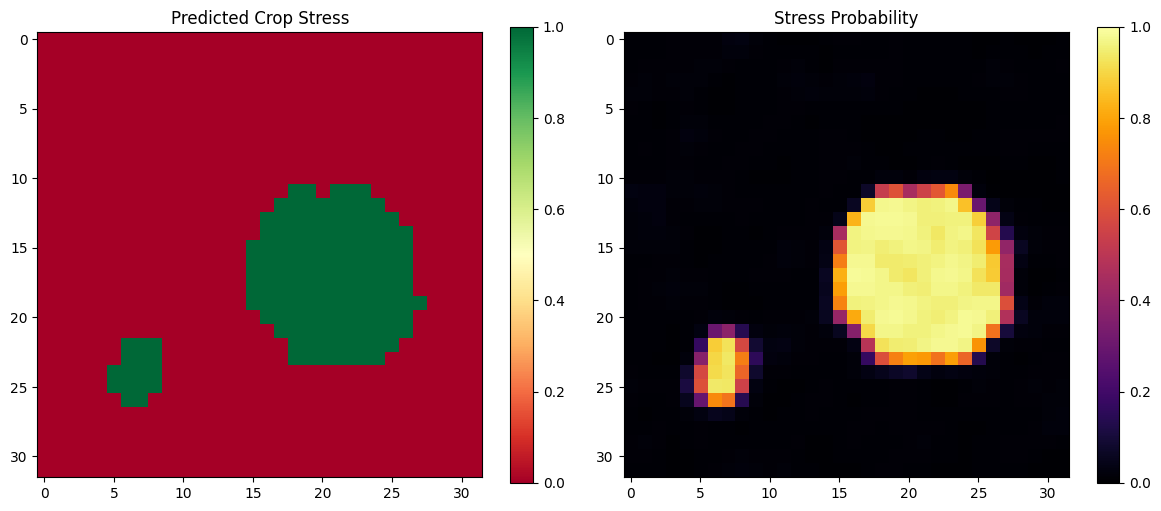

In [50]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.imshow(
    prediction_map,
    cmap="RdYlGn",
    vmin=0,
    vmax=1
)

plt.title("Predicted Crop Stress")
plt.colorbar()

plt.subplot(1, 2, 2)

plt.imshow(
    confidence_map,
    cmap="inferno",
    vmin=0,
    vmax=1
)

plt.title("Stress Probability")
plt.colorbar()

plt.tight_layout()
plt.show()


In [51]:
import os

os.makedirs("artifacts", exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_shape": [1, 16, 3, 3],
        "num_classes": 2,
        "class_names": ["Healthy", "Stress"]
    },
    "artifacts/terraspectra_cnn.pth"
)